# Analyze misclassified examples and their characteristics by manually clustering error cases, detecting anomalies in feature distributions, and performing root-cause analysis to determine if specific subgroups are disproportionately affected.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, confusion_matrix

import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("heart.csv")

print(df.head())
print(df.shape)
print(df.isnull().sum())

target = "HeartDisease"

X = df.drop(columns=[target])
y = df[target].astype(int)

   Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR  \
0   40   M           ATA        140          289          0     Normal    172   
1   49   F           NAP        160          180          0     Normal    156   
2   37   M           ATA        130          283          0         ST     98   
3   48   F           ASY        138          214          0     Normal    108   
4   54   M           NAP        150          195          0     Normal    122   

  ExerciseAngina  Oldpeak ST_Slope  HeartDisease  
0              N      0.0       Up             0  
1              N      1.0     Flat             1  
2              N      0.0       Up             0  
3              Y      1.5     Flat             1  
4              N      0.0       Up             0  
(918, 12)
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak          

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

num_cols = X_train.select_dtypes(include=np.number).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=np.number).columns.tolist()

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.9021739130434783


In [4]:
results = X_test.copy()

results["Actual"] = y_test
results["Predicted"] = y_pred

results["Error_Type"] = np.where(
    (results["Actual"] == 0) & (results["Predicted"] == 1),
    "False Positive",
    np.where(
        (results["Actual"] == 1) & (results["Predicted"] == 0),
        "False Negative",
        "Correct"
    )
)

errors = results[results["Error_Type"] != "Correct"].copy()

print("Total Misclassified:", len(errors))
print(errors.head(10))

print(errors["Error_Type"].value_counts())

Total Misclassified: 18
     Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  \
763   58   M           NAP        132          224          0        LVH   
1     49   F           NAP        160          180          0     Normal   
840   41   M           ATA        135          203          0     Normal   
21    44   M           ATA        120          184          0     Normal   
314   53   M           ASY         80            0          0     Normal   
307   53   M           ATA        130            0          0         ST   
636   48   M           ATA        130          245          0        LVH   
434   63   M           ASY        126            0          0         ST   
889   59   M            TA        134          204          0     Normal   
440   52   M           NAP        128            0          0         ST   

     MaxHR ExerciseAngina  Oldpeak ST_Slope  Actual  Predicted      Error_Type  
763    173              N      3.2       Up       1       

In [5]:
X_test_processed = model.named_steps["preprocessor"].transform(X_test)

if hasattr(X_test_processed, "toarray"):
    X_test_processed = X_test_processed.toarray()

error_mask = (y_test.to_numpy() != y_pred)

X_error = X_test_processed[error_mask]

if len(X_error) >= 2:

    n_clusters = min(3, len(X_error))

    kmeans = KMeans(
        n_clusters=n_clusters,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_error)

    errors["Cluster"] = cluster_labels

    print(errors.groupby("Cluster")["Error_Type"].value_counts())

else:
    print("Not enough error cases for clustering.")

Cluster  Error_Type    
0        False Negative    5
         False Positive    5
1        False Positive    4
         False Negative    1
2        False Positive    2
         False Negative    1
Name: count, dtype: int64


Cluster Summary
           Age  RestingBP  Cholesterol  FastingBS   MaxHR  Oldpeak
Cluster                                                           
0        49.30     137.90        212.3        0.0  161.00     0.77
1        55.60     118.80         41.4        0.0  131.40     1.64
2        62.33     164.67          0.0        0.0  127.67     0.83


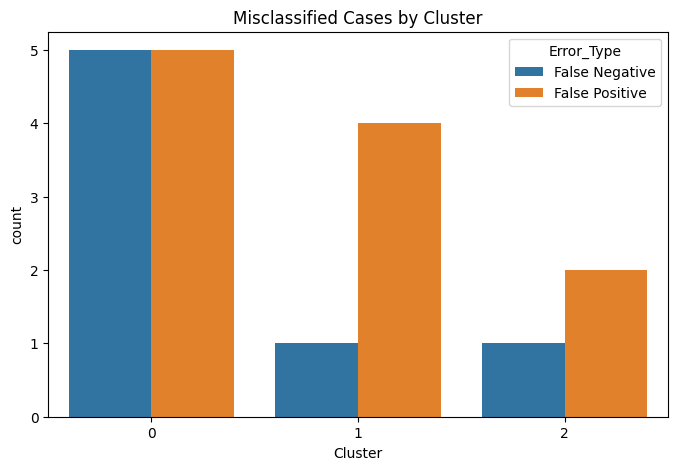

In [6]:
if "Cluster" in errors.columns:

    print("Cluster Summary")

    print(
        errors.groupby("Cluster")[num_cols].mean().round(2)
    )

    plt.figure(figsize=(8, 5))

    sns.countplot(
        data=errors,
        x="Cluster",
        hue="Error_Type"
    )

    plt.title("Misclassified Cases by Cluster")
    plt.show()

In [7]:
if len(X_error) >= 5:

    isolation_model = IsolationForest(
        contamination=0.10,
        random_state=42
    )

    anomaly_labels = isolation_model.fit_predict(X_error)

    errors["Anomaly"] = np.where(
        anomaly_labels == -1,
        "Anomaly",
        "Normal"
    )

    print(errors["Anomaly"].value_counts())

    print(
        errors[errors["Anomaly"] == "Anomaly"]
    )

else:
    print("Not enough error cases for anomaly detection.")

Anomaly
Normal     16
Anomaly     2
Name: count, dtype: int64
     Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  \
1     49   F           NAP        160          180          0     Normal   
314   53   M           ASY         80            0          0     Normal   

     MaxHR ExerciseAngina  Oldpeak ST_Slope  Actual  Predicted  \
1      156              N      1.0     Flat       1          0   
314    141              Y      2.0     Down       0          1   

         Error_Type  Cluster  Anomaly  
1    False Negative        0  Anomaly  
314  False Positive        1  Anomaly  


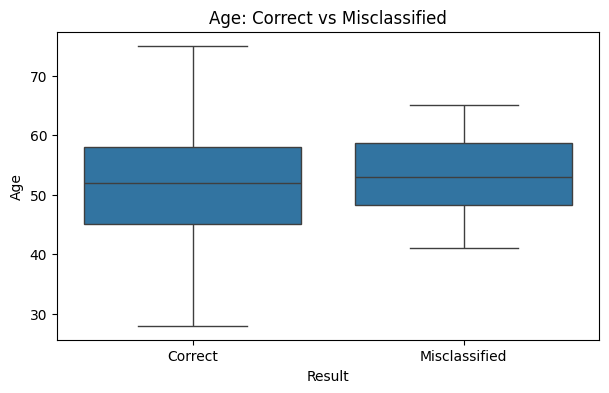

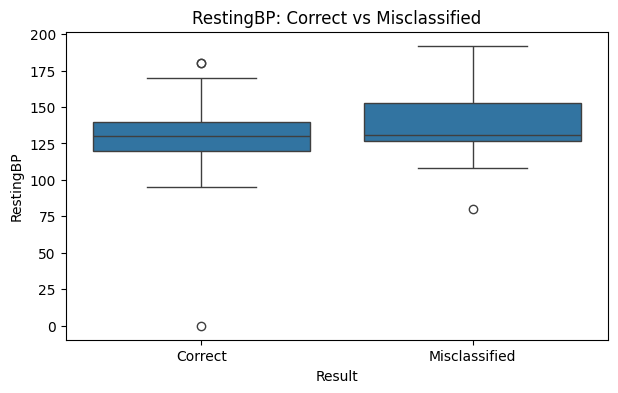

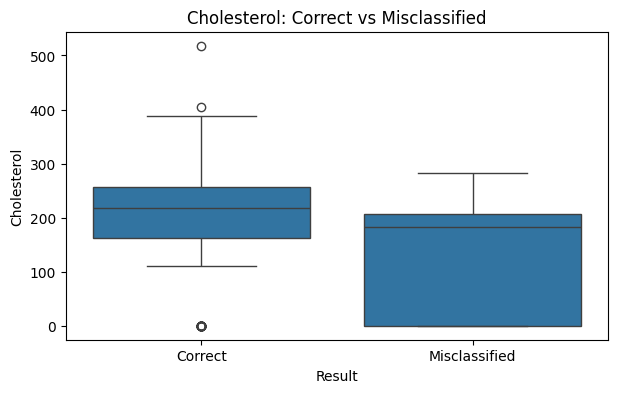

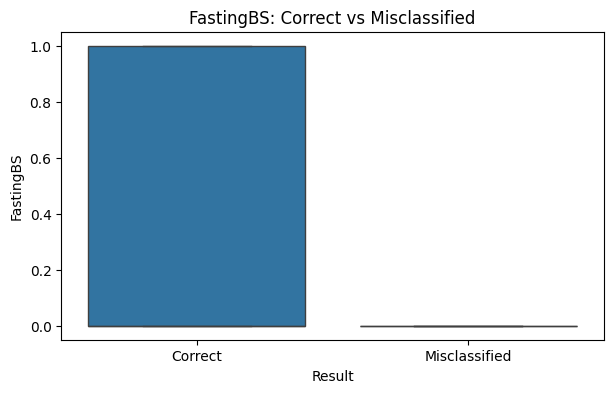

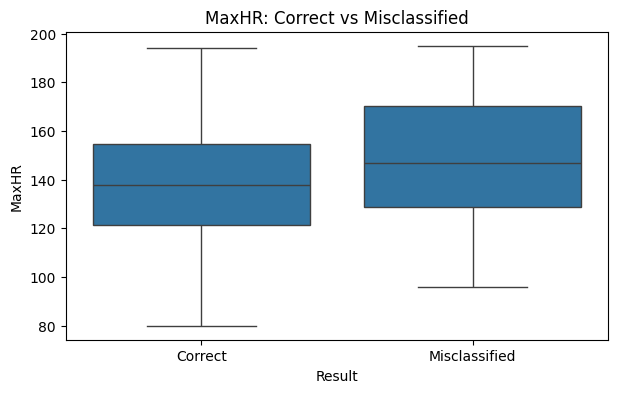

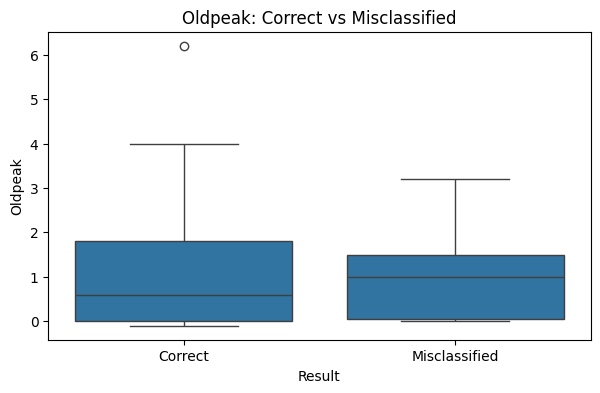

In [8]:
comparison = X_test.copy()

comparison["Result"] = np.where(
    error_mask,
    "Misclassified",
    "Correct"
)

for col in num_cols:

    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=comparison,
        x="Result",
        y=col
    )

    plt.title(f"{col}: Correct vs Misclassified")
    plt.show()